In [3]:
import import_first

from common import (deploy_utils, feature_utils, plot_utils, cluster_utils)

from pathlib import PurePath

import time
import numpy as np
import matplotlib.pyplot as plt

## **1. Get data**

In [4]:
trace = deploy_utils.Trace.read_trace(
    file_path=PurePath("..") / ".." / "data" / "6_to_8am.csv")
print("trace summary:\n" + deploy_utils.Trace.summarize_trace(trace=trace))

trace summary:
[+] number of vehicles: 75516
[+] number of lines: 2182717
[+] x interval: [0, 99]
[+] y interval: [0, 99]


In [5]:
v_df = feature_utils.Features.create_basic_vehicle_df(trace=trace)

In [6]:
v_df.head()

,trip_duration,trip_length,trip_speed,radius_of_gyration,entropy
vehicle_id,,,,,
0,280,16,0.057143,3.166598,3.896292
1,660,35,0.053030,9.093438,4.847520
2,400,27,0.067500,6.107182,4.534184
3,230,14,0.060870,2.945942,3.675311
4,740,41,0.055405,9.749632,5.136696


<Axes: >

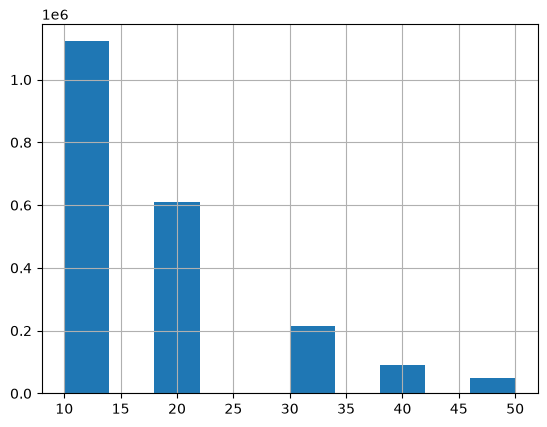

In [7]:
trace[trace["cell_dwell_time"]<=trace["cell_dwell_time"].quantile(q=0.95)]["cell_dwell_time"].hist()

In [8]:
v_df_no_outl = cluster_utils.Preprocessing.remove_outliers(
    df=v_df, features=v_df.columns.tolist())

In [9]:
v_df, _ = cluster_utils.Preprocessing.do_standard_scale(df=v_df, features=v_df.columns.tolist())

In [10]:
v_df.head()

,trip_duration,trip_length,trip_speed,radius_of_gyration,entropy
vehicle_id,,,,,
0,-0.956085,-0.685207,0.686673,-0.692637,-0.222071
1,0.205044,0.323697,0.378576,0.711783,0.675063
2,-0.589413,-0.101105,1.462592,0.004162,0.379546
3,-1.108865,-0.791407,0.965864,-0.744924,-0.430485
4,0.449492,0.642298,0.556510,0.867275,0.947794


In [11]:
v_df_no_outl, _ = cluster_utils.Preprocessing.do_standard_scale(df=v_df_no_outl, features=v_df_no_outl.columns.tolist())

In [12]:
v_df_no_outl.head()

,trip_duration,trip_length,trip_speed,radius_of_gyration,entropy
vehicle_id,,,,,
0,-1.038844,-0.705692,0.784765,-0.712115,-0.230341
1,0.338332,0.479953,0.451551,0.930883,0.770392
2,-0.603946,-0.019266,1.623937,0.103054,0.440749
3,-1.220051,-0.830496,1.086716,-0.773284,-0.462822
4,0.628264,0.854367,0.643990,1.112789,1.074617


## **2. Data Distribution**

### 2.1 Features Histogram (total / no outliers)

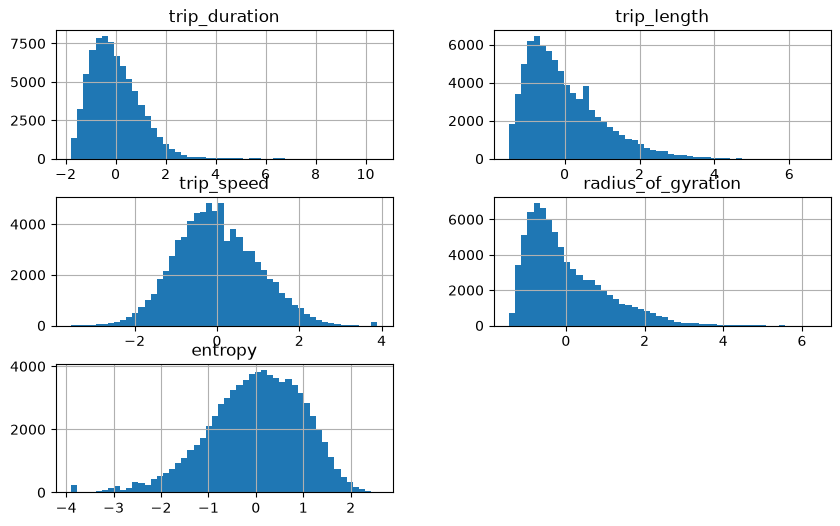

In [13]:
v_df.hist(figsize=(10, 6), bins=50) ; plt.show()

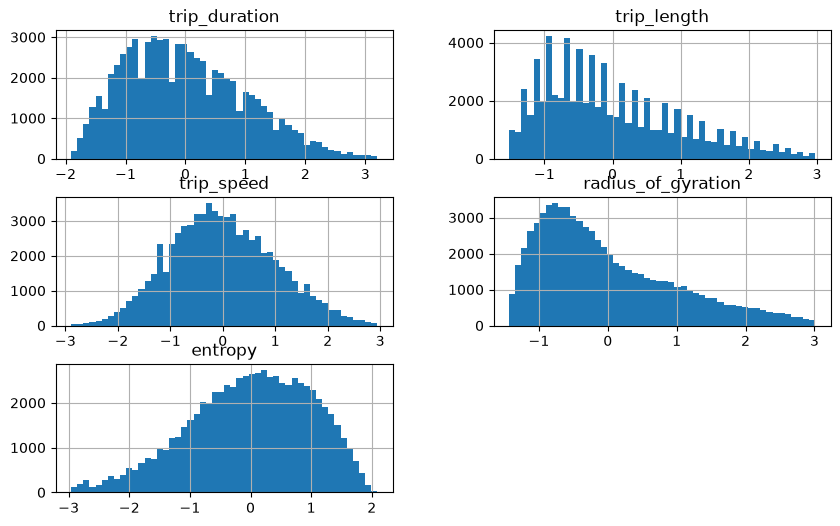

In [14]:
v_df_no_outl.hist(figsize=(10, 6), bins=50) ; plt.show()

### 2.2 Correlation matrix (no outliers)

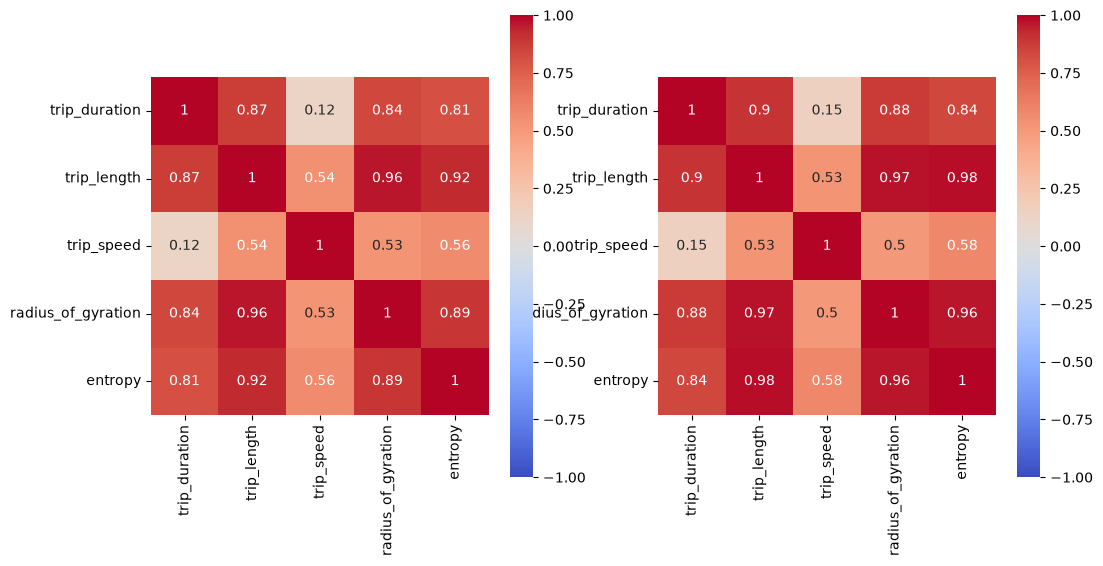

In [15]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 6))

plot_utils.Plot.plot_correlation_matrix(
    df=v_df_no_outl,
    features=v_df.columns.tolist(),
    method="pearson",
    ax=ax[0]
)

plot_utils.Plot.plot_correlation_matrix(
    df=v_df_no_outl,
    features=v_df.columns.tolist(),
    method="spearman",
    ax=ax[1]
)
plt.show()

### 2.3 2D Histograms

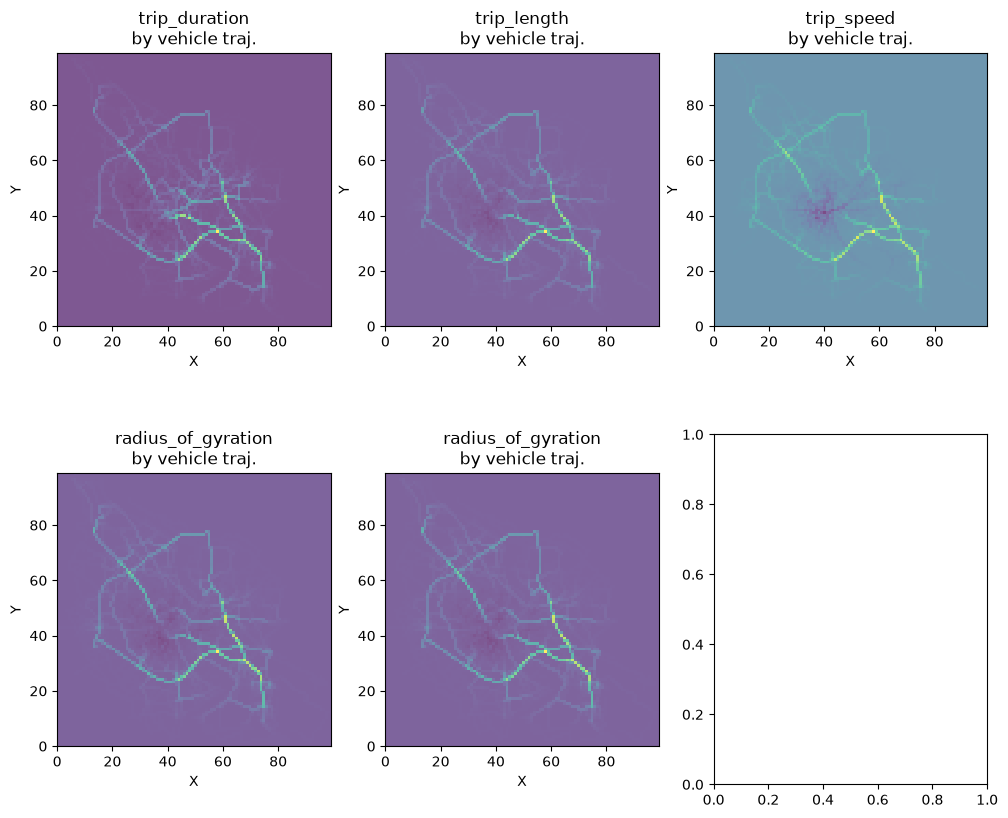

In [16]:
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(12, 10))

plot_utils.Plot.plot_vehicle_feature_2d_histogram(
    trace=trace, vehicle_df=v_df,
    feature="trip_duration", ax=ax[0, 0], trajectory=True, weighted_dwell_time=False)
plot_utils.Plot.plot_vehicle_feature_2d_histogram(
    trace=trace, vehicle_df=v_df,
    feature="trip_length", ax=ax[0, 1], trajectory=True, weighted_dwell_time=False)
plot_utils.Plot.plot_vehicle_feature_2d_histogram(
    trace=trace, vehicle_df=v_df,
    feature="trip_speed", ax=ax[0, 2], trajectory=True, weighted_dwell_time=False)
plot_utils.Plot.plot_vehicle_feature_2d_histogram(
    trace=trace, vehicle_df=v_df,
    feature="radius_of_gyration", ax=ax[1, 0], trajectory=True, weighted_dwell_time=False)
plot_utils.Plot.plot_vehicle_feature_2d_histogram(
    trace=trace, vehicle_df=v_df,
    feature="radius_of_gyration", ax=ax[1, 1], trajectory=True, weighted_dwell_time=False)

plt.show()

## **3. Data distribution (20%)**

In [17]:
import random
rng = random.Random(x=123)

v_sample = rng.sample(population=v_df.index.tolist(), k=int(len(v_df) * 0.2))
v_df_20_p = v_df.loc[v_sample]

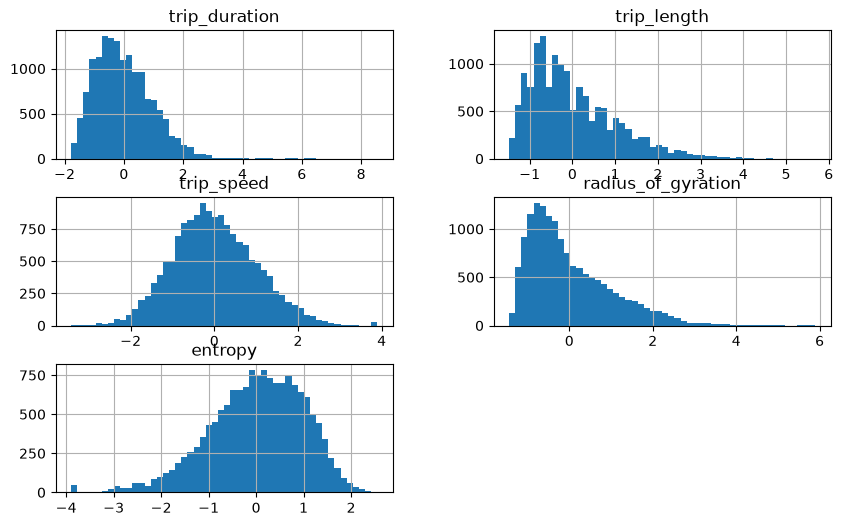

In [18]:
v_df_20_p.hist(figsize=(10, 6), bins=50) ; plt.show()

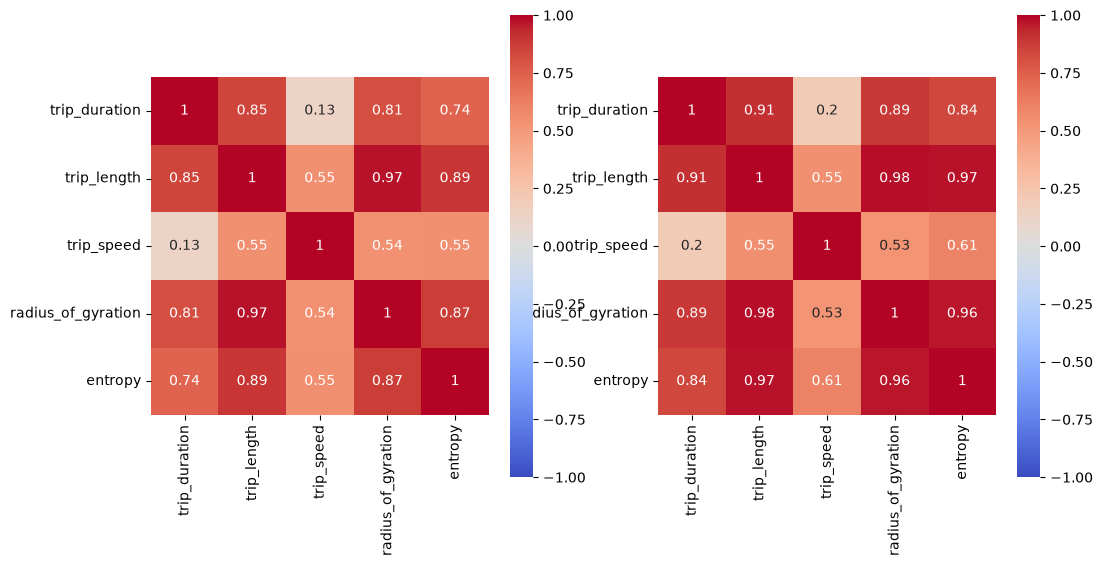

In [19]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 6))

plot_utils.Plot.plot_correlation_matrix(
    df=v_df_20_p,
    features=v_df.columns.tolist(),
    method="pearson",
    ax=ax[0]
)

plot_utils.Plot.plot_correlation_matrix(
    df=v_df_20_p,
    features=v_df.columns.tolist(),
    method="spearman",
    ax=ax[1]
)
plt.show()

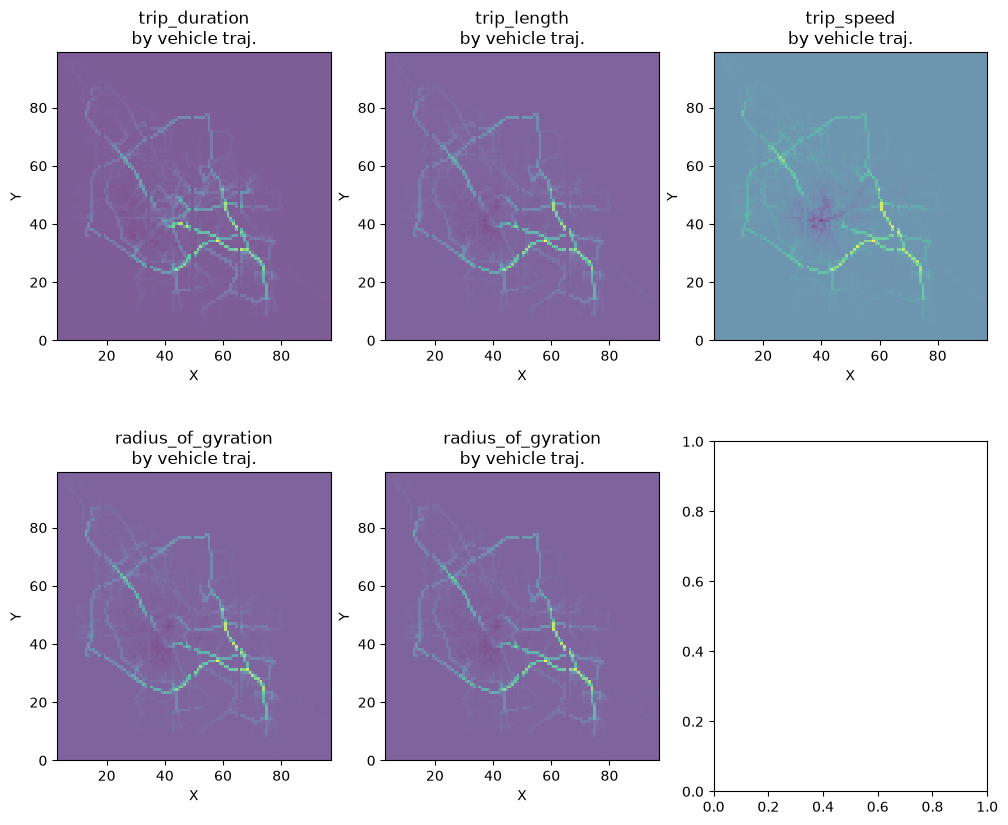

In [20]:
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(12, 10))

plot_utils.Plot.plot_vehicle_feature_2d_histogram(
    trace=trace, vehicle_df=v_df_20_p,
    feature="trip_duration", ax=ax[0, 0], trajectory=True, weighted_dwell_time=False)
plot_utils.Plot.plot_vehicle_feature_2d_histogram(
    trace=trace, vehicle_df=v_df_20_p,
    feature="trip_length", ax=ax[0, 1], trajectory=True, weighted_dwell_time=False)
plot_utils.Plot.plot_vehicle_feature_2d_histogram(
    trace=trace, vehicle_df=v_df_20_p,
    feature="trip_speed", ax=ax[0, 2], trajectory=True, weighted_dwell_time=False)
plot_utils.Plot.plot_vehicle_feature_2d_histogram(
    trace=trace, vehicle_df=v_df_20_p,
    feature="radius_of_gyration", ax=ax[1, 0], trajectory=True, weighted_dwell_time=False)
plot_utils.Plot.plot_vehicle_feature_2d_histogram(
    trace=trace, vehicle_df=v_df_20_p,
    feature="radius_of_gyration", ax=ax[1, 1], trajectory=True, weighted_dwell_time=False)

plt.show()